In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import random
import torch
from matplotlib import pyplot as plt


In [3]:
from dl_utils import synthetic_data
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)
print('features:', features[0],'\nlabel:', labels[0])
print('features:',features)

features: tensor([-0.6330, -0.8118]) 
label: tensor([5.6891])
features: tensor([[-0.6330, -0.8118],
        [ 1.3582, -1.0140],
        [-0.2925,  0.5946],
        ...,
        [-0.5669, -0.4569],
        [ 1.1368,  2.0203],
        [ 1.0193, -0.1895]])


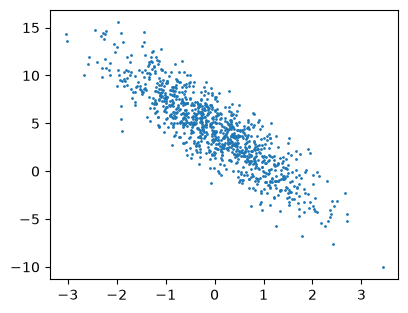

In [4]:
plt.figure(figsize=(4.5, 3.5))
plt.scatter(
    features[:, 1].detach().numpy(),
    labels.detach().numpy(),
    s = 1
)
plt.show()

In [5]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))

    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i:min(i+batch_size, num_examples)]
        )
        yield features[batch_indices], labels[batch_indices]

In [6]:
batch_size  = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.3777,  0.1936],
        [-0.2676, -1.0797],
        [-0.6161,  0.0289],
        [ 0.0964,  1.0593],
        [-0.0679,  1.6917],
        [ 0.8339,  0.1190],
        [-1.9847,  1.1224],
        [ 0.4557, -0.7275],
        [-0.0640,  0.1903],
        [ 1.2301, -0.0794]]) 
 tensor([[ 2.7803],
        [ 7.3464],
        [ 2.8710],
        [ 0.8029],
        [-1.6800],
        [ 5.4766],
        [-3.5749],
        [ 7.5687],
        [ 3.4256],
        [ 6.9322]])


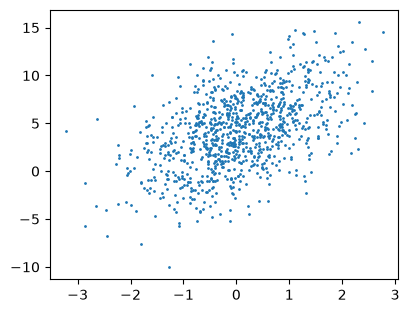

In [7]:
plt.figure(figsize=(4.5, 3.5))
plt.scatter(
    features[:, 0].detach().numpy(),
    labels.detach().numpy(),
    s = 1
)
plt.show()

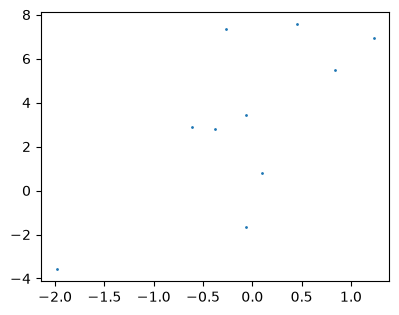

In [8]:
plt.figure(figsize=(4.5, 3.5))
plt.scatter(
    X[:,0].detach().numpy(),
    y.detach().numpy(),
    s = 1
)
plt.show()

In [9]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)


In [10]:
def linreg(X, w, b):
    return torch.matmul(X, w) + b

In [11]:
def squared_loss(y_hat, y):
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

In [12]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

In [13]:
lr = 0.03
num_epochs = 3
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        l.sum().backward()
        sgd([w, b], lr, batch_size)
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

epoch 1, loss 0.035113
epoch 2, loss 0.000123
epoch 3, loss 0.000047


In [14]:
print(f'w的估计误差：{true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差：{true_b - b}')

w的估计误差：tensor([-0.0002, -0.0004], grad_fn=<SubBackward0>)
b的估计误差：tensor([0.0005], grad_fn=<RsubBackward1>)
